# Multi-step LSTM forecasting with PyTorch


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import MinMaxScaler

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## Helper functions

In [6]:
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
    """Turn a univariate or multivariate series into lagged input/output columns."""
    n_vars = 1 if isinstance(data, list) else data.shape[1]
    df = pd.DataFrame(data)
    cols, names = [], []

    for i in range(n_in, 0, -1):
        cols.append(df.shift(i))
        names += [f"var{j+1}(t-{i})" for j in range(n_vars)]

    for i in range(n_out):
        cols.append(df.shift(-i))
        names += [f"var{j+1}(t+{i})" if i else f"var{j+1}(t)"
                  for j in range(n_vars)]

    result = pd.concat(cols, axis=1)
    result.columns = names
    if dropnan:
        result.dropna(inplace=True)
    return result


def difference(values, interval=1):
    """Difference a 1D array: x[t] - x[t-interval]."""
    values = np.asarray(values).reshape(-1)
    return values[interval:] - values[:-interval]


def prepare_data(series, n_test, n_lag, n_seq):
    """Difference, scale, create supervised windows, and split chronologically."""
    raw_values = np.asarray(series).reshape(-1)
    diff_values = difference(raw_values, interval=1).reshape(-1, 1)

    scaler = MinMaxScaler(feature_range=(-1, 1))
    scaled_values = scaler.fit_transform(diff_values)

    supervised = series_to_supervised(scaled_values, n_lag, n_seq)
    values = supervised.to_numpy(dtype=np.float32)

    if n_test <= 0 or n_test >= len(values):
        raise ValueError("n_test must be positive and smaller than the number of windows.")

    train, test = values[:-n_test], values[-n_test:]
    return scaler, train, test


def inverse_difference(last_observation, forecast):
    """Convert forecasted differences back to levels."""
    forecast = np.asarray(forecast).reshape(-1)
    levels = []
    previous = float(last_observation)
    for difference_value in forecast:
        previous = previous + float(difference_value)
        levels.append(previous)
    return levels


def inverse_transform(series, forecasts, scaler, n_test):
    """Invert scaling and differencing for each forecast window."""
    values = np.asarray(series).reshape(-1)
    inverted = []

    for i, forecast in enumerate(forecasts):
        forecast = np.asarray(forecast).reshape(-1, 1)
        inverse_scaled = scaler.inverse_transform(forecast).reshape(-1)

        # The forecast window starts immediately after this observation.
        index = len(values) - n_test + i - 1
        last_observation = values[index]
        inverted.append(inverse_difference(last_observation, inverse_scaled))

    return inverted

## PyTorch LSTM model and training

In [7]:
class MultiStepLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=12, forecast_horizon=48):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )
        self.output = nn.Linear(hidden_size, forecast_horizon)

    def forward(self, x):
        # x: (batch, sequence_length, input_size)
        sequence_output, _ = self.lstm(x)
        last_hidden = sequence_output[:, -1, :]
        return self.output(last_hidden)  # (batch, forecast_horizon)


def fit_lstm(train, n_lag, n_seq, n_batch=1, n_epochs=30, n_neurons=12,
             learning_rate=1e-3, validation_fraction=0.1):
    """Train a direct multi-output LSTM and return model plus loss histories."""
    X = train[:, :n_lag].reshape(-1, n_lag, 1)
    y = train[:, n_lag:n_lag + n_seq]

    split = int(len(X) * (1 - validation_fraction))
    if split <= 0 or split >= len(X):
        raise ValueError("Not enough training windows for the requested validation split.")

    X_train, X_val = X[:split], X[split:]
    y_train, y_val = y[:split], y[split:]

    train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
    train_loader = DataLoader(train_ds, batch_size=n_batch, shuffle=False)

    model = MultiStepLSTM(hidden_size=n_neurons, forecast_horizon=n_seq).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history_loss, history_val_loss = [], []

    for epoch in range(n_epochs):
        model.train()
        running_loss, n_seen = 0.0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            predictions = model(xb)
            loss = criterion(predictions, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(xb)
            n_seen += len(xb)

        train_loss = running_loss / n_seen

        model.eval()
        with torch.no_grad():
            val_x = torch.tensor(X_val, dtype=torch.float32, device=device)
            val_y = torch.tensor(y_val, dtype=torch.float32, device=device)
            val_loss = criterion(model(val_x), val_y).item()

        history_loss.append(train_loss)
        history_val_loss.append(val_loss)
        print(f"Epoch {epoch + 1:>3}/{n_epochs} | "
              f"train loss: {train_loss:.6f} | val loss: {val_loss:.6f}")

    return model, history_loss, history_val_loss


def forecast_lstm(model, X):
    """Forecast the full horizon from one input window of lagged differences."""
    model.eval()
    x = np.asarray(X, dtype=np.float32).reshape(1, -1, 1)
    with torch.no_grad():
        prediction = model(torch.tensor(x, device=device)).cpu().numpy()[0]
    return prediction.tolist()


def make_forecasts(model, test, n_lag, n_seq):
    forecasts = []
    for row in test:
        X = row[:n_lag]
        forecasts.append(forecast_lstm(model, X)[:n_seq])
    return forecasts

## Load the data


Mounted at /content/drive/


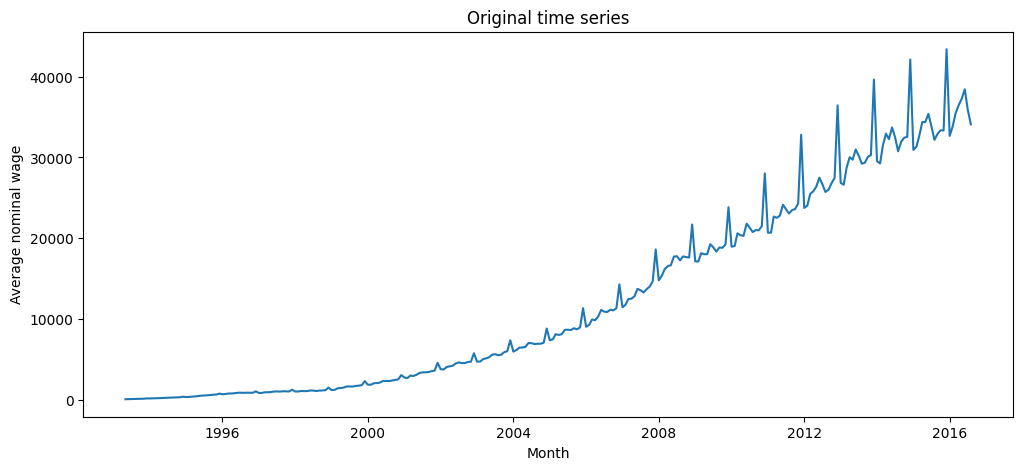

month
1993-05-01    37.5
1993-06-01    47.4
1993-07-01    56.0
1993-08-01    65.4
1993-09-01    80.9
Name: WAG_C_M, dtype: float64


In [8]:

from google.colab import drive
drive.mount('/content/drive/')

DATA_PATH = '/content/drive/My Drive/WAG_C_M.csv'
TARGET_COLUMN = None

data = pd.read_csv(
    DATA_PATH,
    sep=';',
    index_col='month',
    parse_dates=['month'],
    dayfirst=True,
    encoding='cp1251'
)

if TARGET_COLUMN is None:
    target = data.iloc[:, 0]
else:
    target = data[TARGET_COLUMN]

target = target.dropna().astype(float)

plt.figure(figsize=(12, 5))
plt.plot(target)
plt.ylabel('Average nominal wage')
plt.xlabel('Month')
plt.title('Original time series')
plt.show()

print(target.head())

## Inspect the supervised-learning windows

In [9]:
# Example: 12 lagged months used to predict the next 6 months
windows_preview = series_to_supervised(target.to_numpy().reshape(-1, 1), n_in=12, n_out=6)
windows_preview.head()

,var1(t-12),var1(t-11),var1(t-10),var1(t-9),var1(t-8),var1(t-7),var1(t-6),var1(t-5),var1(t-4),var1(t-3),var1(t-2),var1(t-1),var1(t),var1(t+1),var1(t+2),var1(t+3),var1(t+4),var1(t+5)
12,37.5,47.4,56.0,65.4,80.9,93.0,101.5,141.2,134.2,144.7,164.8,171.5,183.5,207.5,221.0,232.8,253.2,265.0
13,47.4,56.0,65.4,80.9,93.0,101.5,141.2,134.2,144.7,164.8,171.5,183.5,207.5,221.0,232.8,253.2,265.0,281.6
14,56.0,65.4,80.9,93.0,101.5,141.2,134.2,144.7,164.8,171.5,183.5,207.5,221.0,232.8,253.2,265.0,281.6,354.2
15,65.4,80.9,93.0,101.5,141.2,134.2,144.7,164.8,171.5,183.5,207.5,221.0,232.8,253.2,265.0,281.6,354.2,302.6
16,80.9,93.0,101.5,141.2,134.2,144.7,164.8,171.5,183.5,207.5,221.0,232.8,253.2,265.0,281.6,354.2,302.6,321.0


## Configure, train, and forecast

In [50]:
# The main code sample - configure hyperparameters of the model
# LSTM is very sensitive to the choice of hyperparameters


# Historical input window and forecast horizon
n_lag = 24
n_seq = 48

# Number of final supervised windows reserved as test windows
n_test = 1

n_epochs = 25
n_batch = 1
n_neurons = 64

scaler, train, test = prepare_data(target, n_test, n_lag, n_seq)

model, history_loss, history_val_loss = fit_lstm(
    train,
    n_lag=n_lag,
    n_seq=n_seq,
    n_batch=n_batch,
    n_epochs=n_epochs,
    n_neurons=n_neurons
)

forecasts_scaled = make_forecasts(model, test, n_lag, n_seq)
forecasts = inverse_transform(target, forecasts_scaled, scaler, n_test)


Epoch   1/25 | train loss: 0.024834 | val loss: 0.144695
Epoch   2/25 | train loss: 0.024286 | val loss: 0.143699
Epoch   3/25 | train loss: 0.024110 | val loss: 0.141132
Epoch   4/25 | train loss: 0.023465 | val loss: 0.131169
Epoch   5/25 | train loss: 0.019404 | val loss: 0.099984
Epoch   6/25 | train loss: 0.015757 | val loss: 0.096249
Epoch   7/25 | train loss: 0.015345 | val loss: 0.094010
Epoch   8/25 | train loss: 0.015005 | val loss: 0.090275
Epoch   9/25 | train loss: 0.014445 | val loss: 0.083665
Epoch  10/25 | train loss: 0.013405 | val loss: 0.074203
Epoch  11/25 | train loss: 0.012000 | val loss: 0.064370
Epoch  12/25 | train loss: 0.010459 | val loss: 0.055548
Epoch  13/25 | train loss: 0.009270 | val loss: 0.049639
Epoch  14/25 | train loss: 0.008252 | val loss: 0.043590
Epoch  15/25 | train loss: 0.007125 | val loss: 0.036656
Epoch  16/25 | train loss: 0.005552 | val loss: 0.028592
Epoch  17/25 | train loss: 0.003687 | val loss: 0.021085
Epoch  18/25 | train loss: 0.00

## Plot the final forecast

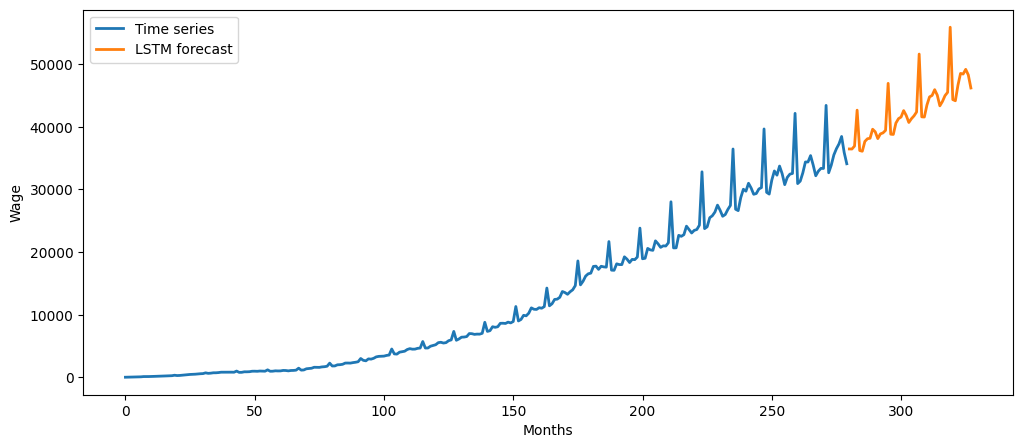

In [53]:

forecast_x = np.arange(len(target), len(target) + n_seq)
forecast_y = forecasts[-1]

plt.figure(figsize=(12, 5))
plt.plot(np.arange(len(target)), target.to_numpy(), linewidth=2, label='Time series')
plt.plot(forecast_x, forecast_y, linewidth=2, label='LSTM forecast')
plt.ylabel('Wage')
plt.xlabel('Months')
plt.legend()
plt.show()

## Plot training and validation losses

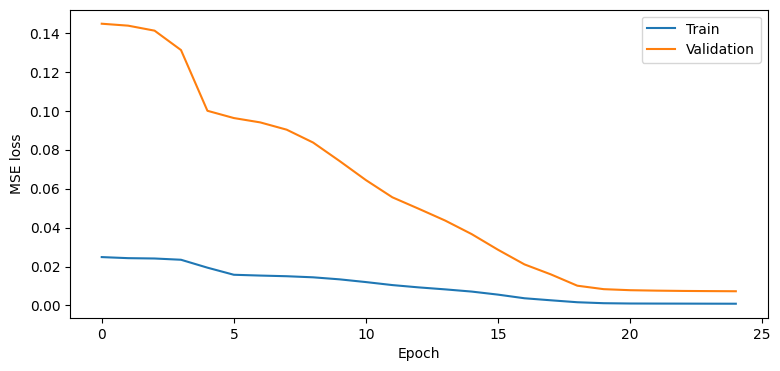

Final train loss: 0.000883
Final validation loss: 0.007289


In [54]:
plt.figure(figsize=(9, 4))
plt.plot(history_loss, label='Train')
plt.plot(history_val_loss, label='Validation')
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.legend()
plt.show()

print(f"Final train loss: {history_loss[-1]:.6f}")
print(f"Final validation loss: {history_val_loss[-1]:.6f}")